> **Joint-forecasting handoff:** [notebook 05](05_r2kmeans_methodology_audit.ipynb) compares fixed currency groups and supplies aligned neural inputs/targets. The optional scalar Ridge audit addresses a different architecture and does not decide this use case. This notebook retains the R2K paper reference.

# Robust Rolling K-Means for the currency panel

**Paper implementation and FX adaptation · November 2026**

Holmes, Hirsa, Klinkert and Malhotra (6 March 2024), [*Robust Rolling K-Means (R2K-Means): an Updateable Nonlinear K-Means Clustering Methodology for Financial Time Series*](https://ssrn.com/abstract=4729393).

The question here is whether currencies can be grouped in a way that updates every month while preserving cluster identities. We implement Algorithm 2, demonstrate its behavior on synthetic data, then apply it to the project's local BIS snapshot. This is an FX adaptation: the paper's mutual-fund data and proprietary performance measures are not available here.

**How to run.** From the repository root, install `python -m pip install -e ".[dev]"`, select that environment's Python kernel, and run all cells. If needed, first run `python scripts/download_data.py` and `python scripts/process_data.py`. The notebook works from the root or `notebooks/`, makes no network requests, and writes reproducible results and figures to `reports/clustering/r2kmeans/`. A full run usually takes less than a minute on this dataset; hardware and versions affect timing.

## 1. What changes relative to the earlier clustering notebooks?

DTW grouped entire return histories; correlation clustering compared co-movement over a fixed window. R2K-Means instead consumes **one asset-by-feature cross section at each date**, so both the locations and memberships can evolve.

| Object | In this notebook |
|---|---|
| Assets $F$ | Eligible members of the selected 39-currency roster |
| Features $D$ | Trailing annualized mean FX log change and annualized FX volatility |
| Time $T$ | Consecutive monthly updates, January 1995–August 2026 by default |
| $K$ | Fixed at 3 for a prespecified illustration; compare 2–6 before 2010 |
| $W$ | 1, 6 and 12 monthly centroid states, including the current state |

This implements a grouping method that could later inform shared-network training or routing. Cluster separation and low turnover do not establish better exchange-rate forecasts.

In [1]:
from pathlib import Path
import sys
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "config/research_sample.json").is_file()
             and (p / "src/fx_forecasting").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the repository checkout.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from fx_forecasting.models.rolling_kmeans import RobustRollingKMeans
from fx_forecasting.data.rolling_features import (
    FEATURES, load_selected_fx, make_rolling_features, normalize_cross_section,
)
from fx_forecasting.evaluation.rolling_clustering import (
    run_bis_experiment, run_cross_sections, summarize_experiment,
)
from fx_forecasting.evaluation.rolling_plots import (
    COLORS, plot_diagnostics, plot_membership, plot_snapshot,
)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
OUTPUT = ROOT / "reports/clustering/r2kmeans"
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED, K, WINDOWS = 42, 3, (1, 6, 12)
START, EVALUATION_START, LOOKBACK = "1995-01", "2010-01", 12
print(f"Python {platform.python_version()} | outputs: {OUTPUT.relative_to(ROOT)}")

Python 3.15.2 | outputs: reports/clustering/r2kmeans


## 2. Algorithm 2, step by step

1. **First month:** fit ordinary K-Means. We use seeded k-means++ with 10 starts, an allowed first-period variant. Assign initial IDs once, ordered by current cluster size.
2. **Later months:** visit previous centroids in ascending order of their previous **Lloyd cluster counts**. Each selects its nearest current feature location not already claimed by another centroid. Duplicate observations at the same coordinates count as one location.
3. **Refine:** run Lloyd K-Means from those selected points with exactly one start. Each centroid keeps its identity. Sorting controls selection priority; it never renames cluster IDs.
4. **Classify:** store the new centroids and label each asset by the closest centroid among the last $\min(t,W)$ states:

$$\ell_{i,t}=\underset{j\in\{0,\ldots,K-1\}}{\operatorname{argmin}}\;\underset{s=\max(1,t-W+1),\ldots,t}{\min}\;\|x_{i,t}-\mu_{j,s}\|_2^2.$$

The rolling bank uses up to $K W$ locations sharing $K$ identities. It does **not** average centroids and does not vote over past labels. With $W=1$, labels come from current centroids only. With larger $W$, unions of Voronoi cells can be nonconvex or disconnected; their boundaries remain piecewise linear.

The paper does not fully specify normalization, ties, or numerical convergence. Here, equal-size clusters choose in ID order, equal-distance assets in sorted currency order, and historical distance ties favor newer centroids. The implementation uses zero Lloyd tolerance and fails before committing a nonconverged or collapsed update. The rolling labels can leave a label temporarily unused even when all current Lloyd clusters are nonempty.

## 3. Synthetic check: unchanged data and reproducible updates

Separated stationary clouds should not acquire turnover merely because time advances. This is a controlled example, not a proof that every possible stationary configuration or initial seed must converge to identical labels. The paper's stability claims should be assessed empirically; deterministic updates can still depend on the initial solution.

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

rng = np.random.default_rng(SEED)
stationary = pd.DataFrame(rng.normal(size=(90, 2)),
                          index=[f"asset_{i:03}" for i in range(90)],
                          columns=["return", "risk"])
stationary.iloc[:30] += [-4, -1]
stationary.iloc[30:60] += [0, 4]
stationary.iloc[60:] += [4, -1]
rolling = RobustRollingKMeans(3, window=6, random_state=SEED)
first = rolling.update(stationary)
last = first
for _ in range(15):
    last = rolling.update(stationary)

raw_labels = []
with threadpool_limits(limits=1):
    for seed in range(16):
        raw_labels.append(KMeans(3, n_init=1, random_state=seed,
                                 algorithm="lloyd").fit_predict(stationary))
raw_switch = np.mean([np.mean(a != b) for a, b in zip(raw_labels, raw_labels[1:])])
raw_ari = np.mean([adjusted_rand_score(a, b) for a, b in zip(raw_labels, raw_labels[1:])])
display(pd.DataFrame([
    {"method": "R2K stationary example", "identity_switch_rate": first.labels.ne(last.labels).mean(),
     "ARI_first_vs_last": adjusted_rand_score(first.labels, last.labels)},
    {"method": "Independent K-Means, 1 start", "identity_switch_rate": raw_switch,
     "ARI_first_vs_last": raw_ari},
]))

,method,identity_switch_rate,ARI_first_vs_last
0,R2K stationary example,0.000000,1.0
1,"Independent K-Means, 1 start",0.622222,1.0


A pure permutation can make every numerical label change while leaving the partition unchanged. The synthetic baseline above deliberately uses one start to expose the paper's initialization concern. The empirical baseline below uses **10 starts** and also receives Hungarian label alignment, making it a stronger comparison. Neither seed-induced label changes nor an arbitrary ID number carry an economic interpretation.

## 4. Synthetic dynamics and actual decision regions

The next example moves three groups in feature space, then compares current-only and rolling classification. Centroid paths are updated from the same data and first-period seed. A rolling classifier can inherit old territory even after the current centroid moves away.

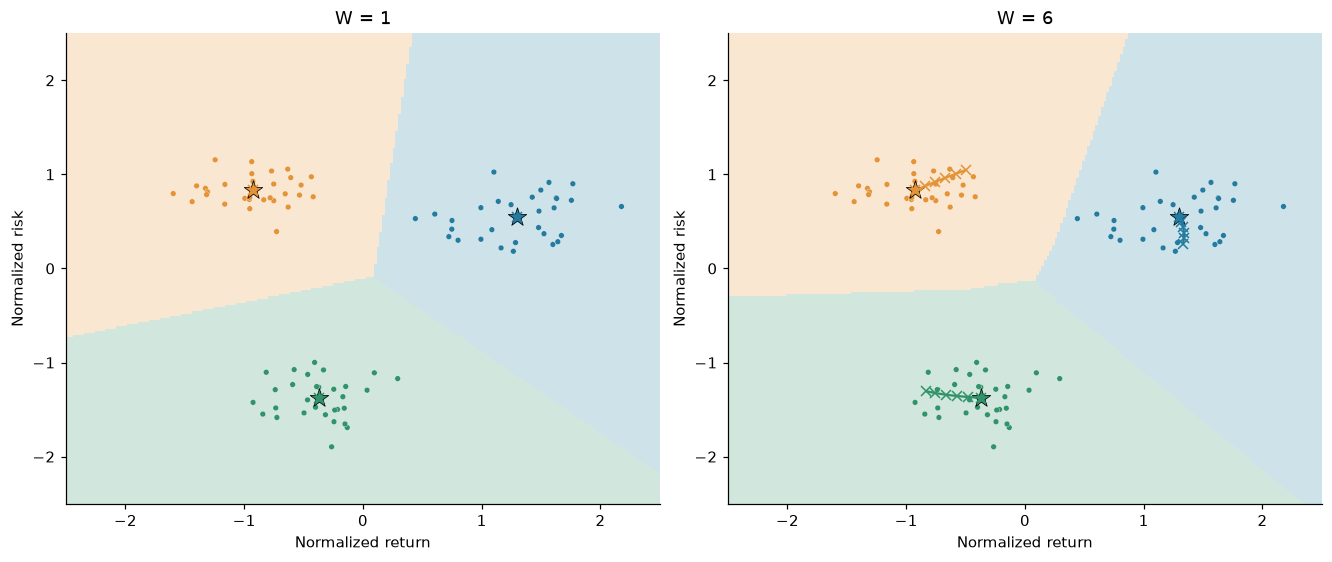

In [3]:
rng = np.random.default_rng(19)
base_centers = np.array([[-2.2, 0.0], [1.8, -1.6], [1.8, 1.6]])
noise = rng.normal(0, .45, (90, 2))
synthetic_frames = []
synthetic_models = {w: RobustRollingKMeans(K, w, random_state=SEED) for w in (1, 6)}
for t in range(24):
    theta = .06 * t
    rotation = np.array([[np.cos(theta), -np.sin(theta)],
                         [np.sin(theta), np.cos(theta)]])
    locations = np.repeat(base_centers @ rotation.T, 30, axis=0) + noise
    frame = pd.DataFrame(locations, index=stationary.index, columns=["return", "risk"])
    frame, _ = normalize_cross_section(frame)
    synthetic_frames.append(frame)
    for model in synthetic_models.values():
        model.update(frame)

xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 220), np.linspace(-2.5, 2.5, 220))
query = pd.DataFrame({"return": xx.ravel(), "risk": yy.ravel()},
                     index=[f"grid_{i}" for i in range(xx.size)])
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, (window, model) in zip(axes, synthetic_models.items()):
    from matplotlib.colors import ListedColormap
    labels = model.predict(query).to_numpy().reshape(xx.shape)
    ax.pcolormesh(xx, yy, labels, cmap=ListedColormap(COLORS[:K]), vmin=-.5, vmax=K-.5,
                  shading="auto", alpha=.22)
    frame = synthetic_frames[-1]
    ax.scatter(frame.iloc[:, 0], frame.iloc[:, 1], c=model.predict(frame),
               cmap=ListedColormap(COLORS[:K]), vmin=-.5, vmax=K-.5, s=14, edgecolor="white", linewidth=.2)
    for cluster in range(K):
        path = model.centroid_history_[:, cluster]
        ax.plot(path[:, 0], path[:, 1], "x-", color=COLORS[cluster])
        ax.scatter(*path[-1], s=160, marker="*", c=COLORS[cluster], edgecolor="black", linewidth=.5)
    ax.set(title=f"W = {window}", xlabel="Normalized return", ylabel="Normalized risk",
           xlim=(-2.5, 2.5), ylim=(-2.5, 2.5))
fig.savefig(OUTPUT / "synthetic_boundaries.png", dpi=160)
plt.show()

## 5. The FX adaptation and information timing

Use the existing `config/research_sample.json`: exact source IDs, 39 distinct currencies, launch dates and inclusive ARS/CNY/MYR exclusions. Do not fill missing or nonpositive FX. A trailing window is eligible only when every monthly return in it is observed, so histories restart after gaps and peg exclusions.

For $q_{i,t}$ measured in **local currency units per USD**, define $r_{i,t}=100\,[\log q_{i,t}-\log q_{i,t-1}]$. Positive values mean local-currency **depreciation**. The two inputs at month end $t$ are

$$m_{i,t}=12\,\overline{r}_{i,t-11:t}, \qquad v_{i,t}=\sqrt{12}\,\mathrm{sd}_{\mathrm{ddof}=1}(r_{i,t-11:t}).$$

They are percent log-change and annualized percent volatility. The mean is annualized even when the lookback is changed. We use these FX measures rather than claim to reproduce the paper's mutual-fund return, Fairway Average, or Risk of Target inputs.

Normalize each feature across the **currently eligible** currencies at the current month (z-score, ddof=0). Constant features map to zero and are flagged. No future dates enter scaling, K-Means fitting, or labels. Each historical centroid stays in the normalized coordinates in which it was estimated; it is not rescaled later. This describes relative cross-sectional positions: changing membership or dispersion can move coordinates even when a currency's raw behavior changes little.

The cross section is unbalanced. Entrants and exits are audited, not filled; fewer than $K$ distinct eligible locations causes an explicit error. All three windows receive the same inputs. BIS revised histories and retrospective regime exclusions make this a historical experiment, not a real-time vintage reconstruction. The word “robust” in the method's name does not imply an outlier-resistant loss: squared Euclidean distances remain sensitive to crises and extremes, which we retain.

In [4]:
fx, currency_metadata, sample_spec = load_selected_fx()
raw_features = make_rolling_features(fx, lookback=LOOKBACK)
features = raw_features.loc[raw_features.index.get_level_values("period") >= pd.Period(START, "M")]
coverage = features.notna().all(axis=1).groupby(level="period").sum()
display(pd.DataFrame({"statistic": ["Configured currencies", "Monthly updates", "Minimum eligible", "Latest eligible"],
                      "value": [len(fx.columns), len(coverage), int(coverage.min()), int(coverage.iloc[-1])]}))
display(features.xs(features.index.get_level_values("period").max(), level="period").round(3))

,statistic,value
0,Configured currencies,39
1,Monthly updates,380
2,Minimum eligible,33
3,Latest eligible,38


,annual_log_change,annualized_volatility
currency,,
ARS,13.123,8.694
AUD,-9.306,8.961
BAM,0.283,5.482
BRL,-4.793,9.255
CAD,0.975,5.824
CHF,0.661,6.752
CLP,-4.039,11.854
CNY,-5.967,2.000
COP,-22.703,11.386


## 6. Run chronological comparisons

We initialize in January 1995 and carry the state forward through the available snapshot. The first 12 updates are treated as burn-in. Report empirical comparisons from January 2010, keeping the earlier history for initialization.

| Method | New-month fit | Classification |
|---|---|---|
| `kmeans_raw` | Independent K-Means, 10 starts and a new reproducible seed each month | Current centroids, arbitrary IDs |
| `kmeans_aligned` | The very same independent fit | IDs matched to previous centroids using Hungarian assignment |
| `r2k_w1` | Previous-centroid snapping, one Lloyd start | Current centroids |
| `r2k_w6` | Identical R2K fit | Last 6 centroid states |
| `r2k_w12` | Identical R2K fit | Last 12 centroid states |

Label alignment removes some numerical relabeling but cannot resolve every ambiguous crossing. Since W changes only classification, the R2K centroid paths and Lloyd inertia should match for every W. Euclidean silhouette is primarily a **W=1** separation diagnostic, as in paper §6.1; its convex-cluster preference makes comparisons with W>1 descriptive rather than a criterion for choosing W.

In [5]:
result, summary, manifest = run_bis_experiment(
    output_dir=OUTPUT, start=START, evaluation_start=EVALUATION_START,
    n_clusters=K, windows=WINDOWS, lookback=LOOKBACK, seed=SEED, tune_k=True,
)
display(summary.round(4))
print(f"Saved {len(result.labels):,} currency-month-method labels across {len(result.coverage)} monthly updates.")

,model,n_months,mean_assets,switch_rate,mean_ari,mean_silhouette,mean_centroid_displacement,mean_min_cluster_size,fraction_months_min_cluster_lt5,mean_rolling_disagreement,mean_lloyd_inertia_per_asset
0,kmeans_aligned,200,38.905,0.1446,0.6663,0.4980,0.5671,3.710,0.710,0.0000,0.5639
1,kmeans_raw,200,38.905,0.5734,0.6663,0.4980,1.8964,3.710,0.710,0.0000,0.5639
2,r2k_w1,200,38.905,0.0967,0.7311,0.4778,0.4026,3.905,0.660,0.0000,0.6172
3,r2k_w12,200,38.905,0.1094,0.6867,0.3819,0.4026,4.335,0.620,0.1527,0.6172
4,r2k_w6,200,38.905,0.1022,0.7034,0.4235,0.4026,4.235,0.605,0.0899,0.6172


Saved 71,590 currency-month-method labels across 380 monthly updates.


**Reading the table.** Switch rates count label changes among currencies present in both adjacent months, divided by the total common-asset count. ARI measures partition similarity after allowing arbitrary label permutations; higher values indicate more similar groupings. Summary ARI and silhouette average monthly scores. Centroid displacement is in normalized feature coordinates. No transaction costs or trading returns are being estimated.

In [6]:
indexed = summary.set_index("model")
raw, aligned, w1, w6 = (indexed.loc[name] for name in ("kmeans_raw", "kmeans_aligned", "r2k_w1", "r2k_w6"))
display(Markdown(
    f"From **{EVALUATION_START}** through **{manifest['settings']['end']}**, "
    f"raw K-Means changes identity on **{raw.switch_rate:.1%}** of common-asset observations; "
    f"alignment reduces this to **{aligned.switch_rate:.1%}** without changing its partitions or silhouette. "
    f"R2K uses **{w6.switch_rate:.1%}** for W=6 and **{w1.switch_rate:.1%}** for W=1. "
    "These are observations for this feature design and initialization, not a general ranking of methods. "
    "A larger centroid history need not reduce turnover or improve separation."
))

From **2010-01** through **2026-08**, raw K-Means changes identity on **57.3%** of common-asset observations; alignment reduces this to **14.5%** without changing its partitions or silhouette. R2K uses **10.2%** for W=6 and **9.7%** for W=1. These are observations for this feature design and initialization, not a general ranking of methods. A larger centroid history need not reduce turnover or improve separation.

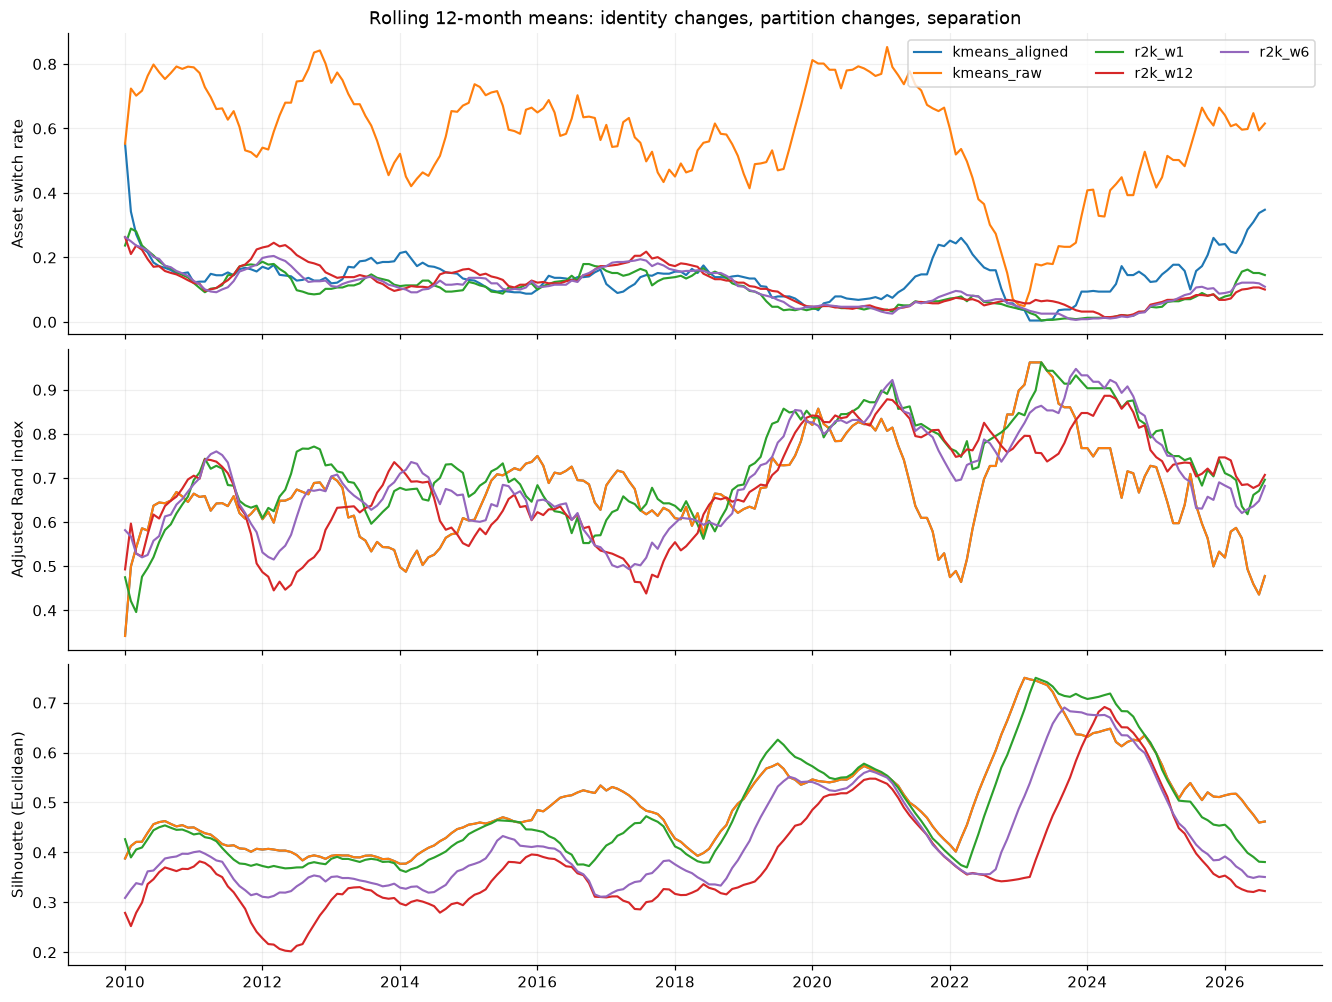

In [7]:
fig = plot_diagnostics(result, start=EVALUATION_START)
fig.savefig(OUTPUT / "diagnostics.png", dpi=160)
plt.show()

## 7. K diagnostics restricted to the pre-2010 period

The K=2–6 diagnostic uses only updates through December 2009, with W=1 and the same 12-update burn-in. Inspect separation together with minimum cluster size: an isolated outlier can make silhouette look attractive while yielding a poor training batch.

We retain K=3 as the paper-style illustration to avoid treating this exploratory notebook as a final model-selection exercise. The table may favor another K. There is no claim that three is optimal, and no post-2010 forecast result is used to select K. Freeze K, W, features and seed rules before a later confirmatory forecast experiment.

,k,calibration_cutoff,mean_silhouette,switch_rate,mean_min_cluster_size
0,2,2009-12,0.5969,0.0580,8.0893
1,3,2009-12,0.4905,0.0992,3.2976
2,4,2009-12,0.4347,0.1461,2.1726
3,5,2009-12,0.3978,0.1626,1.6369
4,6,2009-12,0.3831,0.1855,1.3452


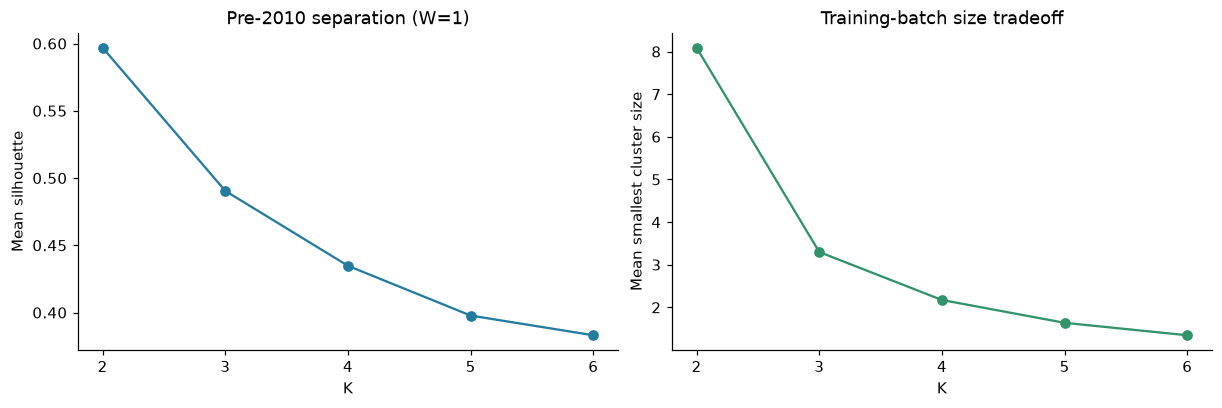

In [8]:
k_grid = pd.read_csv(OUTPUT / "calibration_grid.csv")
display(k_grid[["k", "calibration_cutoff", "mean_silhouette", "switch_rate", "mean_min_cluster_size"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axes[0].plot(k_grid.k, k_grid.mean_silhouette, "o-", color=COLORS[0])
axes[0].set(xlabel="K", ylabel="Mean silhouette", title="Pre-2010 separation (W=1)", xticks=k_grid.k)
axes[1].plot(k_grid.k, k_grid.mean_min_cluster_size, "o-", color=COLORS[2])
axes[1].set(xlabel="K", ylabel="Mean smallest cluster size", title="Training-batch size tradeoff", xticks=k_grid.k)
fig.savefig(OUTPUT / "calibration_k.png", dpi=160)
plt.show()

## 8. Membership histories, coverage and final decision boundary

Cluster numbers describe persistent paths from the first fit, not fixed economic categories. A cluster's meaning can drift. The centroid traces below show the last six normalized states; stars mark current centers. Gray cells in the heatmap are ineligible currency-months rather than an extra cluster.

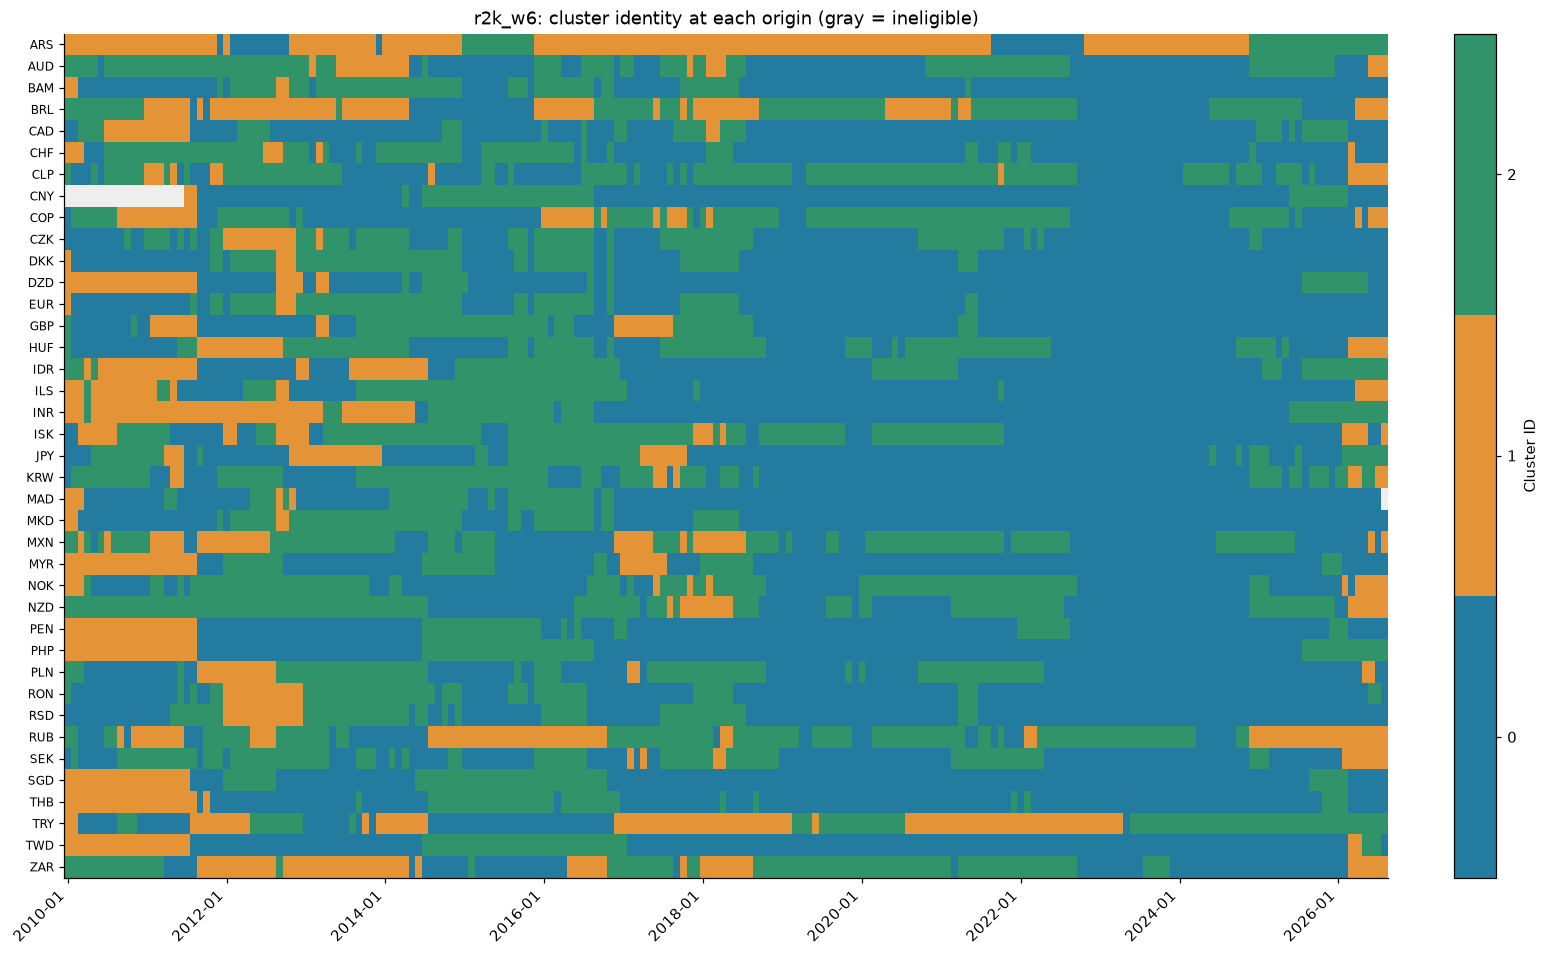

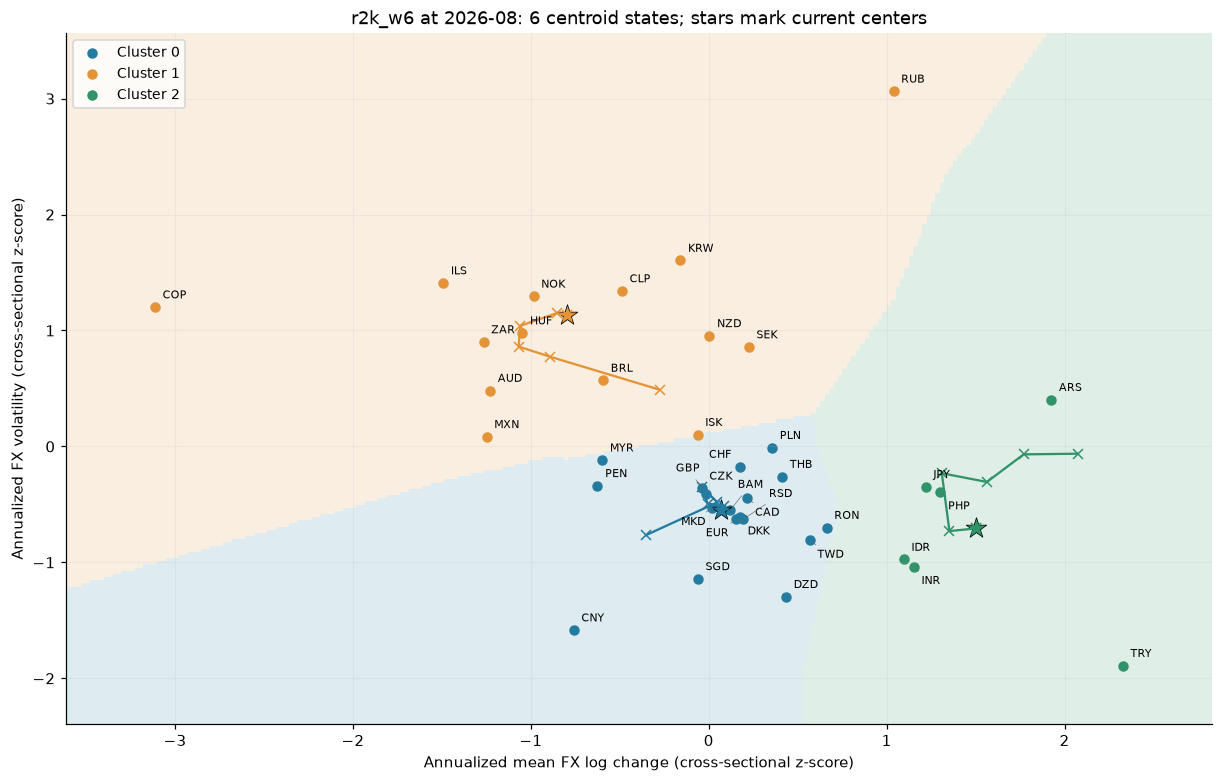

In [9]:
fig = plot_membership(result, model="r2k_w6", start=EVALUATION_START)
fig.savefig(OUTPUT / "membership_w6.png", dpi=160)
plt.show()

fig = plot_snapshot(result, features, model="r2k_w6", window=6)
fig.savefig(OUTPUT / "latest_boundary_w6.png", dpi=160)
plt.show()

In [10]:
latest = result.labels.period.max()
latest_labels = result.labels.loc[result.labels.period.eq(latest) & result.labels.model.eq("r2k_w6")]
latest_table = latest_labels.set_index("currency")[["cluster"]].join(currency_metadata[["economy", "group"]])
latest_table = latest_table.join(features.xs(pd.Period(latest, "M"), level="period"))
display(latest_table.sort_values(["cluster", "annualized_volatility"]).round(3))
display(result.coverage.loc[result.coverage.n_missing.gt(0)].tail(10))

,cluster,economy,group,annual_log_change,annualized_volatility
currency,,,,,
CNY,0,China,emerging_and_developing,-5.967,2.000
DZD,0,Algeria,emerging_and_developing,2.520,2.970
SGD,0,Singapore,advanced,-1.007,3.489
TWD,0,Chinese Taipei,advanced,3.470,4.604
RON,0,Romania,emerging_and_developing,4.142,4.977
RSD,0,Serbia,emerging_and_developing,0.797,5.214
EUR,0,Euro area,advanced,0.533,5.230
DKK,0,Denmark,advanced,0.679,5.281
BAM,0,Bosnia and Herzegovina,emerging_and_developing,0.283,5.482


,period,n_roster,n_eligible,n_missing,n_entrants,n_exits,excluded_currencies
189,2010-10,39,38,1,0,0,CNY
190,2010-11,39,38,1,0,0,CNY
191,2010-12,39,38,1,0,0,CNY
192,2011-01,39,38,1,0,0,CNY
193,2011-02,39,38,1,0,0,CNY
194,2011-03,39,38,1,0,0,CNY
195,2011-04,39,38,1,0,0,CNY
196,2011-05,39,38,1,0,0,CNY
197,2011-06,39,38,1,0,0,CNY
379,2026-08,39,38,1,0,1,MAD


## 9. First-period seed sensitivity

R2K is deterministic after its first fitted state, but its starting seed can still matter. Compare three initial seeds over the **pre-2010 calibration history only**. The full sample above remains the prespecified seed 42 example. The paper's 1,000-simulation figures are not reproduced by this three-seed check.

In [11]:
calibration_features = features.loc[features.index.get_level_values("period") < pd.Period(EVALUATION_START, "M")]
seed_rows = []
for seed in (7, 42, 99):
    check = run_cross_sections(calibration_features, n_clusters=K, windows=(6,),
                               seed=seed, baselines=False)
    row = summarize_experiment(check, START).iloc[0].to_dict()
    seed_rows.append({"seed": seed, **row})
seed_sensitivity = pd.DataFrame(seed_rows)
seed_sensitivity.to_csv(OUTPUT / "seed_sensitivity.csv", index=False)
display(seed_sensitivity[["seed", "switch_rate", "mean_ari", "mean_silhouette"]].round(4))

,seed,switch_rate,mean_ari,mean_silhouette
0,7,0.0985,0.7274,0.4608
1,42,0.0985,0.7274,0.4608
2,99,0.0985,0.7274,0.4608


## 10. Incremental use and the link to forecasting

The reusable model consumes a DataFrame with assets as rows, a fixed feature schema and finite values. Advance it once per new month, in chronological order; `predict` does not update the state. Asset membership may change. A production service would persist the model state together with its feature definitions and scaling convention; the saved historical labels here support repeatable research runs.

For this dynamic-regime experiment, use the cluster assigned using information through each origin t. Historical training rows must retain **their own origin-time labels**, with targets realized by the fit date. Do not assign all past rows using the latest cluster map, do not backfill a post-2010 fit into the earlier evaluation, and do not interpret the current cluster number as a permanent country class. Any choice between shared, cluster-specific, or embedding-based networks needs its own expanding-window forecasting comparison against the same benchmark sample.

For fixed joint-forecasting groups, a clustering fit entirely through a training cutoff may legitimately assign the whole training history, then stay frozen for later evaluation. That fold-level use differs from a dynamic origin-time regime descriptor. Keep currency channels fixed in either case; notebook 05 supplies that handoff.

In [12]:
# Small example of maintaining state as two consecutive FX feature cross sections arrive.
months = features.index.get_level_values("period").unique()[-2:]
stream = RobustRollingKMeans(n_clusters=K, window=6, random_state=SEED)
for month in months:
    raw_cross = features.xs(month, level="period").dropna()
    scaled_cross, scaling_audit = normalize_cross_section(raw_cross)
    step = stream.update(scaled_cross)
    print(f"{month}: {len(step.labels)} assets; {len(stream.centroid_history_)} centroid states")
# This two-update model has its own short initialization history; it is not the
# 1995-initialized empirical model above, so its cluster IDs need not match.
display(step.labels.rename("cluster_at_origin").to_frame().head())

2026-07: 39 assets; 1 centroid states
2026-08: 38 assets; 2 centroid states


,cluster_at_origin
currency,
ARS,2
AUD,1
BAM,2
BRL,1
CAD,2


## 11. Reproducibility and limits

The run manifest records source/config hashes, implementation hashes, parameters, package versions and hashes of the core output tables. Additional notebook figures and seed diagnostics are derived artifacts. Raw data are read only. Run `python -m pytest -q` to check seed priority, duplicate coordinates, the nearest-historical-centroid rule, W=1 equivalence, input validation, gap/launch handling, deterministic updates and prefix invariance when future data are appended or changed.

**What this notebook establishes:** a runnable implementation of the paper's update and classification rules, plus a transparent adaptation to the selected FX panel. **What remains an empirical question:** whether these groups improve neural-network forecasts, how sensitive they are to alternative causal features/scaling and historical universes, and whether small or drifting groups are useful training samples. The original paper's data and figures are not reproduced, and its reported performance is not assumed to carry over.

Sources: Holmes et al. (2024), Algorithm 2 and §§5–6, in the supplied March 6 PDF; [SSRN record](https://ssrn.com/abstract=4729393). The numerical Lloyd solver follows the [scikit-learn KMeans API](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html). FX roster and exclusions follow this repository's [sample decision record](../docs/data/sample_and_treatment.md).

In [13]:
display(pd.DataFrame([manifest["environment"]]).T.rename(columns={0: "version"}))
display(pd.DataFrame(manifest["sources"]).T)
print("Core artifacts:", ", ".join(manifest["outputs"]))
print("Manifest:", (OUTPUT / "run_manifest.json").relative_to(ROOT))

,version
python,3.15.2
numpy,2.5.4
pandas,3.1.1
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
pyarrow,26.0.1


,sha256
observations.parquet,91b8d8bb6f246ace06ad1504aa975dfa11ea3faab3a58e...
research_sample.json,c95c0e36bc410074acd292b5ffcfd226fce47aaec26c64...


Core artifacts: centroids.parquet, coverage.csv, currency_metadata.csv, features.parquet, labels.parquet, metrics.csv, normalization.csv, summary.csv, calibration_grid.csv
Manifest: reports/clustering/r2kmeans/run_manifest.json
